# 13 — Fine-tuning with LoRA

**FinRAG learning series · Notebook 13 of 14**

## Learning objectives
1. Explain LLM fine-tuning and supervised fine-tuning (SFT) in plain terms.
2. Understand **LoRA**: why training two small matrices is enough to adapt a large model.
3. Build the training set FinRAG uses (only validated, real extractions; document-level split).
4. Configure PEFT/TRL exactly like `app/fine_tuning/train_lora.py` and count trainable parameters.
5. Compare the base and fine-tuned model on held-out data, and analyse errors.

## Prerequisites
Notebooks 06–07. `requirements-finetune.txt` installed. The base model (Qwen/Qwen3-0.6B) downloaded. A trained adapter in
`backend/app/fine_tuning/output/` for section 6 (the saved run used one trained on CPU on 2026-11-23).

## Concept
A pretrained LLM has learnt language; **supervised fine-tuning** shows it many *(prompt → desired output)* pairs so it adopts a format
or skill. Full fine-tuning updates all weights (hundreds of millions to billions of numbers). **LoRA** freezes them and learns a
low-rank update for selected weight matrices:

```
W' = W + (α / r) · B·A        W: d_out × d_in (frozen)    A: r × d_in,  B: d_out × r  (trainable),  r ≪ d
```
For a 1024×1024 matrix and r = 16 that is 2·16·1024 = 32,768 trainable numbers instead of 1,048,576.

**What FinRAG fine-tunes:** turning one table row into canonical JSON (`{"metric": ..., "values": [...]}`) — a *format* skill.
**What it does not:** company facts. Those always come from retrieval and validated records, never from model weights.

In [1]:
# Setup: make the production backend importable and keep secrets out of outputs
import sys, os
sys.path.insert(0, os.path.abspath("."))      # run notebooks from the notebooks/ folder
import finrag_nb as nb                          # helper: paths, safe settings, DB session
print("Backend package:", nb.BACKEND_DIR)
print("Documents folder:", nb.DOCS_DIR)

Backend package: /home/user/Ready_To_Deploy/backend
Documents folder: /opt/finrag_testdocs


## 1. The training data (built from validated, real extractions)

In [2]:
import json
data_dir = nb.PROJECT_DIR / "data" / "training_data"
stats = json.loads((data_dir / "dataset_stats.json").read_text())
for split in ("train", "test"):
    print(split, {k: stats[split][k] for k in ("examples", "positive", "abstain")}, "documents:", stats[split]["documents"][:3])
train = [json.loads(l) for l in (data_dir / "train.jsonl").read_text().splitlines()]
for e in [e for e in train if e["metric"]][:2] + [e for e in train if not e["metric"]][:1]:
    print("\nINPUT :", e["input"]); print("OUTPUT:", e["output"]); print("source:", e["filename"], e["location"])

train {'examples': 49, 'positive': 33, 'abstain': 16} documents: ['RIL-Integrated-Annual-Report-2023-24.pdf']
test {'examples': 127, 'positive': 85, 'abstain': 42} documents: ['RIL-Integrated-Annual-Report-2024-25.pdf', 'derived_p57.csv', 'derived_p57.docx']

INPUT : Total Current Liabilities | As at 31st March, 2024: 3,97,367 | As at 31st March, 2023: 3,95,743
OUTPUT: {"metric": "total_current_liabilities", "values": [{"period": "As at 31st March, 2024", "value": "3,97,367"}, {"period": "As at 31st March, 2023", "value": "3,95,743"}]}
source: RIL-Integrated-Annual-Report-2023-24.pdf page 110 (printed p. 217)

INPUT : Total Current Assets | As at 31st March, 2024: 4,70,100 | As at 31st March, 2023: 4,25,296
OUTPUT: {"metric": "total_current_assets", "values": [{"period": "As at 31st March, 2024", "value": "4,70,100"}, {"period": "As at 31st March, 2023", "value": "4,25,296"}]}
source: RIL-Integrated-Annual-Report-2023-24.pdf page 110 (printed p. 216)

INPUT : Hathway Bhawani NDS Networ

Positive rows come only from values that passed an accounting identity (or were verified by a person). Abstention rows teach
`"metric": null` for labels that match no canonical pattern. Train and test come from **different documents** (another year's
report), and identical inputs are removed from training. The command that built them:
`python -m app.fine_tuning.build_dataset --test-docs <ids> --out ../data/training_data`.

## 2. LoRA parameter arithmetic for the real model

In [3]:
from transformers import AutoConfig
BASE = "/opt/models/qwen3-0.6b"            # local copy of Qwen/Qwen3-0.6B (or the Hub id)
cfg = AutoConfig.from_pretrained(BASE)
h, inter, L = cfg.hidden_size, cfg.intermediate_size, cfg.num_hidden_layers
q_out, kv_out = cfg.num_attention_heads * cfg.head_dim, cfg.num_key_value_heads * cfg.head_dim
r = 16
shapes = {"q_proj": (h, q_out), "k_proj": (h, kv_out), "v_proj": (h, kv_out), "o_proj": (q_out, h),
          "gate_proj": (h, inter), "up_proj": (h, inter), "down_proj": (inter, h)}
per_layer = sum(r * (din + dout) for din, dout in shapes.values())
print(f"hidden={h} intermediate={inter} layers={L} q_out={q_out} kv_out={kv_out}")
print(f"LoRA r={r}: {per_layer:,} parameters per layer x {L} layers = {per_layer * L:,} trainable parameters (predicted)")

hidden=1024 intermediate=3072 layers=28 q_out=2048 kv_out=1024
LoRA r=16: 360,448 parameters per layer x 28 layers = 10,092,544 trainable parameters (predicted)


## 3. Apply the same LoRA configuration with PEFT

In [4]:
import torch, time
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer
t = time.time()
tok = AutoTokenizer.from_pretrained(BASE)
base = AutoModelForCausalLM.from_pretrained(BASE, dtype=torch.float32)
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
peft_model = get_peft_model(base, lora)
peft_model.print_trainable_parameters()
print(f"(loaded in {time.time() - t:.1f}s)")

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650
(loaded in 58.7s)


The PEFT count matches the hand calculation — LoRA trains under 2% of the weights.

## 4. Training (guarded)
Training the saved adapter took ~10 minutes on 4 CPU cores (manifest below). It is **not** re-run by default. Set `RUN_TRAINING = True`
to retrain with the production script; on a CUDA GPU the script switches to bf16 automatically.

In [5]:
import subprocess, sys
RUN_TRAINING = False
cmd = [sys.executable, "-m", "app.fine_tuning.train_lora", "--model", BASE, "--data", str(data_dir),
       "--out", "app/fine_tuning/output/lora-notebook-run", "--epochs", "3"]
print("command:", " ".join(cmd))
if RUN_TRAINING:
    subprocess.run(cmd, cwd=nb.BACKEND_DIR, check=True)
else:
    print("RUN_TRAINING is False: using the previously trained adapter.")

command: /home/user/Ready_To_Deploy/backend/.venv/bin/python -m app.fine_tuning.train_lora --model /opt/models/qwen3-0.6b --data /home/user/Ready_To_Deploy/data/training_data --out app/fine_tuning/output/lora-notebook-run --epochs 3
RUN_TRAINING is False: using the previously trained adapter.


PREVIOUS TRAINING RUN: {'device': 'cpu (x86_64)', 'train_examples': 49, 'epochs': 3.0, 'lr': 0.0002, 'lora_rank': 16, 'trainable_params': 10092544, 'train_seconds': 582.7, 'train_loss': 0.08131962919082397}


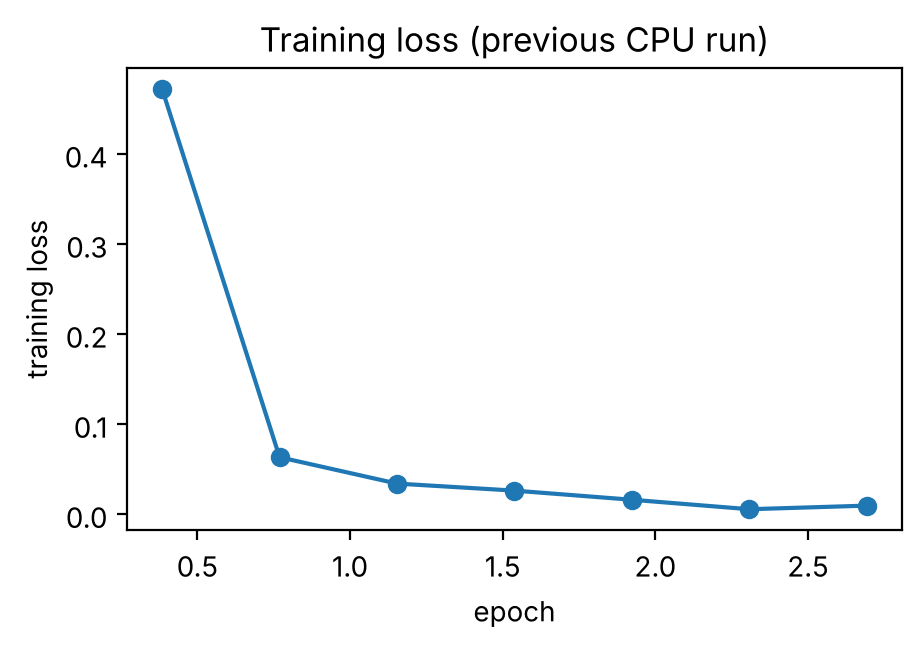

In [6]:
import matplotlib.pyplot as plt
ADAPTER = nb.BACKEND_DIR / "app/fine_tuning/output/lora-extract-v1"
man = json.loads((ADAPTER / "finrag_manifest.json").read_text())
print("PREVIOUS TRAINING RUN:", {k: man[k] for k in ("device", "train_examples", "epochs", "lr", "lora_rank", "trainable_params", "train_seconds", "train_loss")})
hist = [h for h in man["log_history"] if "loss" in h]
plt.figure(figsize=(5, 3)); plt.plot([float(h["epoch"]) for h in hist], [float(h["loss"]) for h in hist], marker="o")
plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("Training loss (previous CPU run)"); plt.show()

A falling training loss only shows the model fits the training rows. Whether it generalises must be measured on held-out data.

## 5. Previous held-out evaluation (recorded 2026-11-23)

In [7]:
import pandas as pd
res = json.loads((ADAPTER / "eval_results.json").read_text())
print("evaluated at:", res["evaluated_at"], "| device:", res["device"], "| held-out examples:", res["lora"]["examples"])
pd.DataFrame({"base (zero-shot)": res["base"], "LoRA": res["lora"]}).drop(index=["examples"])

evaluated at: 2026-11-23T20:13:54.207021+00:00 | device: cpu | held-out examples: 127


,base (zero-shot),LoRA
json_valid,0.00,1.0000
metric_correct,0.00,0.6929
values_exact,0.00,0.7717
fully_correct,0.00,0.6929
positive_fully_correct,0.00,0.7765
abstain_correct,0.00,0.5238
latency_s_mean,16.51,6.7400


## 6. Error analysis of the previous evaluation

In [8]:
from app.financial_analytics.metric_extractor import METRIC_NAMES
canonical = set(METRIC_NAMES) - {"line_item"}
invented, missed, wrong_vals = [], [], 0
for e in res["examples"]:
    try:
        pred = json.loads(e["lora"][e["lora"].index("{"):])
    except Exception:
        continue
    gm, pm = e["gold"]["metric"], pred.get("metric")
    if pm and pm not in canonical:
        invented.append(pm)
    if gm and pm is None:
        missed.append(gm)
    if gm and pm == gm and not e["lora_correct"]:
        wrong_vals += 1
print(f"LoRA predictions with an INVENTED (non-canonical) key: {len(invented)}  e.g. {invented[:5]}")
print(f"real metrics the LoRA model abstained on: {len(missed)}  e.g. {missed[:5]}")
print(f"right metric but wrong/missing values: {wrong_vals}")

LoRA predictions with an INVENTED (non-canonical) key: 29  e.g. ['net_cost_gratuity_funded', 'repayment_of_borrowings_noncurrent_current_maturities', 'discount_rate', 'profit', 'total']
real metrics the LoRA model abstained on: 9  e.g. ['finance_costs', 'finance_costs', 'finance_costs', 'finance_costs', 'deferred_tax']
right metric but wrong/missing values: 0


## 7. New: live inference on three held-out rows

In [9]:
from peft import PeftModel
test = [json.loads(l) for l in (data_dir / "test.jsonl").read_text().splitlines()]
picks = [e for e in test if e["metric"]][:2] + [e for e in test if not e["metric"]][:1]
base_model = peft_model.unload() if hasattr(peft_model, "unload") else base       # back to the plain base weights
base_model.eval()
tuned = PeftModel.from_pretrained(base_model, str(ADAPTER)).eval()

def generate(model, e):
    msgs = [{"role": "system", "content": e["instruction"]}, {"role": "user", "content": e["input"]}]
    ids = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", enable_thinking=False, return_dict=True)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=96, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

for e in picks:
    t = time.time()
    with tuned.disable_adapter():
        b = generate(tuned, e)
    l = generate(tuned, e)
    print("INPUT:", e["input"][:100]); print("GOLD :", e["output"])
    print("BASE :", nb.shorten(b, 200)); print("LORA :", nb.shorten(l, 200)); print(f"({time.time() - t:.1f}s)\n")

INPUT: Total Expenses | 2024-25: 8,92,097 | 2023-24: 8,26,189
GOLD : {"metric": "total_expenses", "values": [{"period": "2024-25", "value": "8,92,097"}, {"period": "2023-24", "value": "8,26,189"}]}
BASE : ```json { "Total Expenses": { "2024-25": "8,92,097", "2023-24": "8,26,189" } } ```
LORA : {"metric": "total_expenses", "values": [{"period": "2024-25", "value": "8,92,097"}, {"period": "2023-24", "value": "8,26,189"}]}
(220.9s)



INPUT: Other Income | 2024-25: 17,978 | 2023-24: 16,057
GOLD : {"metric": "other_income", "values": [{"period": "2024-25", "value": "17,978"}, {"period": "2023-24", "value": "16,057"}]}
BASE : ```json { "Other Income": { "2024-25": 17978, "2023-24": 16057 } } ```
LORA : {"metric": "other_income", "values": [{"period": "2024-25", "value": "17,978"}, {"period": "2023-24", "value": "16,057"}]}
(183.3s)



INPUT: Warehousing and Distribution Expenses | 2024-25: 12,922 | 2023-24: 11,992
GOLD : {"metric": null, "values": []}
BASE : ```json { "metric_key": "Warehousing and Distribution Expenses", "2024-25": "12,922", "2023-24": "11,992" } ```
LORA : {"metric": null, "values": []}
(120.2s)



**What the saved run shows.** On these three held-out rows the adapter produced exactly the gold JSON, including the abstention
(`null`) for *Warehousing and Distribution Expenses*. The base model used its own format and, for *Other Income*, even turned
`17,978` into the number `17978` — losing the printed form FinRAG must preserve. Three rows are an illustration, not a measurement:
over all 127 held-out rows the adapter was fully correct 69.3% of the time (section 5), and section 6 lists the 29 invented keys and
9 missed metrics behind the other 30.7%. The long per-row times in the saved output come from running on a CPU that was busy
reprocessing documents at the same time.

## Interpretation
* The adapter reliably produces the required JSON and copies values faithfully, but it **invents keys** and sometimes abstains on real
  metrics. For production FinRAG keeps the deterministic extractor; any model output would have to be validated against the canonical
  list and the accounting identities.
* The base model's 0% is lopsided by design (no key list or examples in its prompt): it shows the base cannot do *this exact task*
  zero-shot, not that it lacks knowledge. A fair few-shot baseline is a good exercise.
* 49 training rows on CPU is a demonstration of the method, not a production model.

## Common errors and troubleshooting
| Symptom | Cause | Fix |
|---|---|---|
| `TypeError ... warmup_ratio` | Transformers 5 removed it | Use `warmup_steps` (as `train_lora.py` does) |
| Out of memory on CPU | fp32 0.6B + activations | Smaller `--batch`, shorter `--max-length` |
| Loss near 0 but test accuracy low | Overfitting a tiny dataset | More verified data; fewer epochs; evaluate on other documents |
| Base model outputs `<think>` blocks | Qwen3 thinking mode | `enable_thinking=False` in the chat template |

## Practical exercises
1. Build a fair few-shot baseline: put the canonical key list and three examples into the base prompt and re-run section 7.
2. Verify more values in the app, rebuild the dataset, retrain with `RUN_TRAINING = True`, and re-evaluate.
3. Add a post-processing step that maps invented keys to `null` and measure the change in abstention accuracy.

## Summary
You built SFT data from validated extractions, reproduced the LoRA parameter count by hand and with PEFT, reviewed a real CPU training
run and its held-out evaluation, analysed the adapter's errors, and ran live base-vs-LoRA inference.

## Further learning
* LoRA paper: https://arxiv.org/abs/2106.09685
* PEFT: https://huggingface.co/docs/peft · TRL SFTTrainer: https://huggingface.co/docs/trl
* FinRAG: `app/fine_tuning/`, `docs/FINE_TUNING.md`
* Next: **14 — NVIDIA GPU experiments**.